# 02 Validation de la cible

On contrôle la cible du notebook 01 avec des artistes connus, 20 positifs tirés au hasard et les contrats de MusicBrainz. La règle suit les liens ownership et imprint datés, sans les distributeurs. Le disque doit être au moins à moitié en major, avec W = 3 et H = 3. Puis on choisit entre « + imprint » et « + rename », et on mesure l'effet de chaque correction.

In [1]:
import sys
from math import inf

import pandas as pd

sys.path.append("..")
from src.transformation import (
    COHORTES, VARIANTES, annees_de_renommage, charger_sorties, cohorte, en_major, labels_majors, labels_majors_dates,
    labels_sous, liens_labels, lire, premiere_sortie_major, sans_distributeurs, sorties_du_projet,
)

pd.set_option("display.max_colwidth", 80)

liens = liens_labels()
release = charger_sorties()
label_major = sans_distributeurs(labels_majors_dates(liens, VARIANTES["+ imprint"]))
sorties = sorties_du_projet(release, label_major)
premiere_major = premiere_sortie_major(sorties)

artist = lire("artist", ["id", "gid", "name"]).set_index("id")
id_artiste = pd.Series(artist.index, index=artist["gid"])
label = lire("label", ["id", "name"]).set_index("id")
release_label = lire("release_label", ["release", "label"])
infos = lire("release", ["id", "gid", "name"]).set_index("id")

In [2]:
def fiche(artiste, s):
    major = s[(s["artist"] == artiste) & s["major"]]
    ligne = {"artiste": artist.loc[artiste, "name"], "première sortie en major": major["annee"].min()}
    if len(major):
        premiere = major.loc[major["annee"] == major["annee"].min(), "release"].iloc[0]
        labels = release_label.loc[release_label["release"] == premiere, "label"].dropna()
        ligne["titre"] = infos.loc[premiere, "name"]
        ligne["labels"] = ", ".join(label.loc[labels, "name"])
        ligne["lien"] = f"https://musicbrainz.org/release/{infos.loc[premiere, 'gid']}"
    return ligne

## 1. Cas connus et dates des liens

In [3]:
CONNUS = {
    "Vampire Weekend": "af37c51c-0790-4a29-b995-456f98a6b8c9",
    "Arctic Monkeys": "ada7a83c-e3e1-40f1-93f9-3e73dbc9298a",
    "Fontaines D.C.": "fd87acc7-e0a0-4a45-bc2a-d2ab5c10be68",
    "Big Thief": "9f81247f-7f57-42f3-a8ba-75bef554e591",
    "Mac DeMarco": "f2492c31-54a8-4347-a1fc-f81f72873bbf",
}
pd.DataFrame([fiche(id_artiste[gid], sorties) for gid in CONNUS.values()])

,artiste,première sortie en major,titre,labels,lien
0,Vampire Weekend,2019,Father of the Bride,Columbia,https://musicbrainz.org/release/ebc065eb-656b-426a-bf4e-9fd068c9e31e
1,Arctic Monkeys,<NA>,NaN,NaN,NaN
2,Fontaines D.C.,<NA>,NaN,NaN,NaN
3,Big Thief,<NA>,NaN,NaN,NaN
4,Mac DeMarco,<NA>,NaN,NaN,NaN


Vampire Weekend est le seul des cinq à être passé chez une major. Pour les quatre autres, restés chez des indépendants, la règle ne devrait rien trouver.

- Vampire Weekend. Signature chez Columbia rapportée en novembre 2016, premier album Columbia le 3 mai 2019 (Father of the Bride). La règle trouve bien 2019. Sans la règle du disque à moitié en major, ils passaient en major dès 2008. En cause, l'édition japonaise de leur premier album chez Beggars Japan, label de Warner Music Japan de 2006 à 2009 seulement.
- Arctic Monkeys, chez Domino depuis 2005. Aucune sortie en major. Pourtant leur album AM porte Sony Music sur l'édition mexicaine, et EMI Recorded Music Australia (Universal depuis 2013) sur une autre. Ces éditions isolées comptaient avant la correction.
- Fontaines D.C., chez Partisan depuis 2018 puis chez XL. Leur single de reprises de Nick Drake (2023) sort chez Chrysalis, label de Warner de mars 2013 à juin 2016 seulement. Sans les dates des liens, ce single les classait en major (partie 6).
- Big Thief (Saddle Creek puis 4AD) et Mac DeMarco (Captured Tracks puis son propre label) n'ont aucune sortie en major, comme attendu.

In [4]:
vw = id_artiste[CONNUS["Vampire Weekend"]]
pd.Series({t0: cohorte(sorties, t0).get(vw, "hors population") for t0 in range(2016, 2021)}, name="positif")

2016              False
2017               True
2018               True
2019               True
2020    hors population
Name: positif, dtype: object

Vampire Weekend est positif pour T0 = 2017 à 2019. La signature de fin 2016 ne se voit qu'avec l'album de 2019, et H = 3 suffit à la capter dès T0 = 2017.

In [5]:
link = lire("link", ["id", "ended"]).rename(columns={"id": "link"})
arbre = liens[
    liens["type_lien"].isin(VARIANTES["+ imprint"])
    & liens["entity0"].isin(label_major["label"])
    & liens["entity1"].isin(label_major["label"])
].merge(link, on="link")
print(f"{len(arbre)} liens, {arbre['begin_date_year'].notna().mean():.0%} avec une date de début, "
      f"{arbre['end_date_year'].notna().mean():.0%} avec une date de fin, {(arbre['ended'] & arbre['end_date_year'].isna()).sum()} finis sans date de fin")
exemples = label_major[label_major["label"].isin([795, 7108, 1546, 2489, 1705, 59382])]  # Chrysalis, Flying Nun, Sony Classical, Nonesuch, DHM, Universal
exemples = exemples.assign(nom=exemples["label"].map(label["name"]), sorties=exemples["label"].map(release_label["label"].value_counts()))
exemples.drop_duplicates(["nom", "major", "debut", "fin"]).sort_values(["nom", "debut"])

4086 liens, 27% avec une date de début, 13% avec une date de fin, 177 finis sans date de fin


,label,debut,fin,major,nom,sorties
104,795,2012.0,2012.0,Universal,Chrysalis,4633
105,795,2012.0,2013.0,Universal,Chrysalis,4633
4965,795,2013.0,2016.0,Warner,Chrysalis,4633
4966,795,2016.0,2016.0,Warner,Chrysalis,4633
2981,1705,1992.0,inf,Sony,Deutsche Harmonia Mundi,774
2982,1705,2005.0,inf,Sony,Deutsche Harmonia Mundi,774
2983,1705,2006.0,inf,Sony,Deutsche Harmonia Mundi,774
2984,1705,2009.0,inf,Sony,Deutsche Harmonia Mundi,774
5139,7108,2005.0,2009.0,Warner,Flying Nun Records,681
5035,2489,1964.0,1970.0,Warner,Nonesuch,2307


Dans l'arbre des majors, 4 086 liens entre labels, 27 % avec une date de début et 13 % avec une date de fin. Quand elles existent, un label ne compte en major que pendant les dates de ses liens. Un chemin depuis une holding tient entre le dernier début et la première fin de ses liens. Une date inconnue ne limite rien. Chrysalis n'est ainsi chez Warner que de 2013 à 2016, et Flying Nun de 2005 à 2009, deux vraies ventes. Fontaines D.C. n'a donc plus de sortie en major. Les 177 liens finis sans date de fin restent ouverts, faute de mieux.

Sony Classical, Nonesuch et Deutsche Harmonia Mundi restent pourtant en major, alors que leurs liens de propriété s'arrêtent. Exemple avec Sony Classical.

In [6]:
renomme = annees_de_renommage(liens)
fins = arbre[arbre["end_date_year"].notna()]
proches = [any(abs(fin - a) <= 1 for a in renomme.get(e0, set()) | renomme.get(e1, set())) for e0, e1, fin in zip(fins["entity0"], fins["entity1"], fins["end_date_year"])]
print(f"{sum(proches)} des {len(fins)} fins datées de l'arbre tombent à un an près d'un renommage d'un des deux labels")

autour = liens[liens["type_lien"].isin(VARIANTES["+ rename"]) & (
    (liens["entity1"] == 1546) | (liens["entity0"].isin([88432, 1685]) & (liens["type_lien"] == "label rename"))
)]  # Sony Classical, et les renommages de ses deux propriétaires
pd.DataFrame({
    "entity0": autour["entity0"].map(label["name"]),
    "lien": autour["type_lien"],
    "entity1": autour["entity1"].map(label["name"]),
    "début": autour["begin_date_year"],
    "fin": autour["end_date_year"],
}).sort_values("début")

273 des 517 fins datées de l'arbre tombent à un an près d'un renommage d'un des deux labels


,entity0,lien,entity1,début,fin
6122,Sony Music Entertainment Inc.,label ownership,Sony Classical,1990,2005
18153,CBS Records Masterworks,label rename,Sony Classical,1990,1990
12439,Sony Music Entertainment Inc.,label rename,Sony BMG Music Entertainment,2004,2004
33988,Sony BMG Masterworks,label ownership,Sony Classical,2005,2009
6340,Sony Music Masterworks,imprint,Sony Classical,2009,<NA>
826,Sony BMG Masterworks,label rename,Sony Music Masterworks,2009,2009


Ses deux liens de propriété finissent en 2005 et en 2009. C'est à un an près des renommages de Sony Music Entertainment Inc. et de Sony BMG Masterworks. Une fin de lien à un an près d'un renommage d'un des deux labels reste donc ouverte. Le label a changé de nom, il n'a pas été vendu. C'est le cas de 273 des 517 fins datées de l'arbre.

La règle a une limite. « Universal », le label le plus utilisé des exemples, n'est relié à Universal que de 1998 à 2000. Il ne compte donc plus en major ensuite (partie 6).

Pour dire qu'un artiste est déjà passé par une major avant T0, on ne regarde pas les dates. On compare avec une exclusion datée elle aussi.

In [7]:
exclusion_datee = {t0: cohorte(sorties.assign(major_un_jour=sorties["major"]), t0) for t0 in COHORTES}
pd.DataFrame({
    "positifs, exclusion datée": {t0: c.sum() for t0, c in exclusion_datee.items()},
    "positifs, exclusion sans dates": {t0: cohorte(sorties, t0).sum() for t0 in COHORTES},
}).T

,2014,2015,2016,2017,2018,2021
"positifs, exclusion datée",613,669,663,705,688,795
"positifs, exclusion sans dates",471,520,530,587,620,719


In [8]:
labels_majors_sorties = release_label[release_label["label"].isin(label_major["label"])]


def labels_de_majors(releases):
    return set(labels_majors_sorties.loc[labels_majors_sorties["release"].isin(releases), "label"])


rachetes = exclusion_datee[2014][exclusion_datee[2014]].index.difference(cohorte(sorties, 2014).index)
meme_label, exemples = 0, []
for a in rachetes:
    s = sorties[sorties["artist"] == a]
    avant = labels_de_majors(s.loc[s["major_un_jour"] & (s["annee"] < 2014), "release"])
    apres = labels_de_majors(s.loc[s["major"] & s["annee"].between(2014, 2016), "release"])
    meme_label += bool(avant & apres)
    if len(exemples) < 6:
        exemples.append({"artiste": artist.loc[a, "name"], "avant 2014": ", ".join(label.loc[sorted(avant)[:3], "name"]),
                         "de 2014 à 2016": ", ".join(label.loc[sorted(apres)[:3], "name"])})
print(f"{meme_label} sur {len(rachetes)} sortent en major de 2014 à 2016 chez un label qu'ils avaient avant 2014")
pd.DataFrame(exemples)

58 sur 142 sortent en major de 2014 à 2016 chez un label qu'ils avaient avant 2014


,artiste,avant 2014,de 2014 à 2016
0,Cassius,"Virgin, Astralwerks",Interscope Records
1,Roxette,"Parlophone, Warner Music Sweden, EMI Music Japan Inc.","Parlophone, Warner Music Sweden, Parlophone Music Sweden AB"
2,Earth Crisis,Century Media,Spinefarm Records U.K.
3,Marduk,"Century Media, Blooddawn Productions","Century Media, Blooddawn Productions"
4,In Flames,Century Media,"Epic, Sony Music"
5,Ismo Alanko,"Poko Rekords, Seal on Velvet",Sony Music


Avec une exclusion datée, chaque cohorte gagnerait 68 à 149 positifs. En 2014, 58 sur 142 sortent en major chez un label qu'ils avaient déjà avant T0. C'est le cas de Roxette chez Parlophone ou de Marduk chez Century Media. C'est un rachat, pas une signature. Les autres changent de label mais venaient d'un label passé depuis à une major (Cassius chez Virgin, In Flames chez Century Media). On garde l'exclusion sans dates, quitte à perdre de vrais passages en major parmi eux.

## 2. Vingt positifs tirés au hasard

Le tirage (graine 0) se fait parmi les positifs de T0 = 2021 de la règle sans aucune correction. Les liens n'y ont pas de dates, les distributeurs comptent et une seule édition en major suffit. C'est ce contrôle qui a motivé les corrections. Chaque positif est vérifié sur MusicBrainz, puis dans la presse musicale pour la date de signature.

In [9]:
labels_bruts = labels_majors(liens, VARIANTES["+ imprint"]).assign(debut=-inf, fin=inf)
brut = sorties_du_projet(release, labels_bruts, seuil=0)
positifs_bruts = cohorte(brut, 2021)
tirage = pd.Series(positifs_bruts[positifs_bruts].index).sample(20, random_state=0)
controle = pd.DataFrame([fiche(a, brut) for a in tirage], index=tirage.values)

In [10]:
VERDICTS = {
    "Price": ("juste", "premier EP en major, chez Motown, en mars 2022"),
    "Cynthia Erivo": ("juste", "premier album, chez Verve, en septembre 2021"),
    "Drims": ("juste", "album chez Universal Music México en 2021"),
    "Asya Fateyeva": ("juste", "passe de Berlin Classics à Deutsche Harmonia Mundi (Sony)"),
    "WOOSUNG": ("faux", "Warner Music Korea, de type Distributor, sur l'édition coréenne"),
    "KUU!": ("faux", "homonyme, ces singles sont du trio électronique KUU"),
    "FLOHIO": ("discutable", "AWAL, plateforme pour indépendants, à Sony depuis 2021"),
    "Jean‐Michel Blais": ("faux", "déjà chez Mercury Classics en 2019, avec une bande originale"),
    "A.M.C": ("juste", "Drum&BassArena, label de Ministry of Sound (Sony depuis 2016)"),
    "Morgan Wade": ("juste", "signe chez Arista Nashville en août 2021"),
    "Armani White": ("juste", "signe chez Def Jam en juillet 2022"),
    "Misery Index": ("juste", "signe chez Century Media (Sony depuis 2015) en 2020"),
    "Freezy": ("non confirmé", "Sony Music d'après MusicBrainz seulement"),
    "Tems": ("juste", "signe chez Since '93 / RCA en septembre 2021"),
    "dreamcastmoe": ("discutable", "AWAL, plateforme pour indépendants, à Sony depuis 2021"),
    "Nate Smith": ("faux", "homonyme, cet album est du chanteur country Nate Smith"),
    "Faouzia": ("faux", "déjà chez Atlantic en 2020, label absent dans la base"),
    "Mick Jenkins": ("faux", "album chez RBC Records / BMG, l'édition Universal est isolée"),
    "MIST": ("faux", "chez Warner depuis son EP de 2016, label absent dans la base"),
    "sophiemarie.b": ("faux", "300 Entertainment n'est à Warner que depuis décembre 2021"),
}
controle["verdict"] = controle["artiste"].map(lambda a: VERDICTS[a][0])
controle["raison"] = controle["artiste"].map(lambda a: VERDICTS[a][1])
positifs = cohorte(sorties, 2021)
controle["positif après correction"] = controle.index.isin(positifs[positifs].index)
colonnes = ["artiste", "première sortie en major", "labels", "verdict", "raison", "positif après correction"]
display(controle[colonnes].reset_index(drop=True))
pd.crosstab(controle["verdict"], controle["positif après correction"], margins=True)

,artiste,première sortie en major,labels,verdict,raison,positif après correction
0,Price,2022,"CLRD Entertainment, Motown",juste,"premier EP en major, chez Motown, en mars 2022",True
1,Cynthia Erivo,2021,Verve,juste,"premier album, chez Verve, en septembre 2021",True
2,Drims,2021,Universal,juste,album chez Universal Music México en 2021,False
3,Asya Fateyeva,2021,Deutsche Harmonia Mundi,juste,passe de Berlin Classics à Deutsche Harmonia Mundi (Sony),True
4,WOOSUNG,2022,Warner Music Korea,faux,"Warner Music Korea, de type Distributor, sur l'édition coréenne",False
5,KUU!,2021,Warner Records,faux,"homonyme, ces singles sont du trio électronique KUU",True
6,FLOHIO,2022,AWAL Recordings Ltd,discutable,"AWAL, plateforme pour indépendants, à Sony depuis 2021",True
7,Jean‐Michel Blais,2022,Universal,faux,"déjà chez Mercury Classics en 2019, avec une bande originale",True
8,A.M.C,2021,Drum&BassArena,juste,"Drum&BassArena, label de Ministry of Sound (Sony depuis 2016)",True
9,Morgan Wade,2021,"Arista Nashville, Ladylike",juste,signe chez Arista Nashville en août 2021,True


positif après correction,False,True,All
verdict,,,
discutable,0,2,2
faux,3,5,8
juste,1,8,9
non confirmé,0,1,1
All,4,16,20


Sans correction, 9 positifs justes sur 20 et 8 faux. La cible corrigée retire 3 faux (WOOSUNG, Mick Jenkins, sophiemarie.b) et un juste, Drims, sorti chez « Universal » (partie 1). Asya Fateyeva, chez Deutsche Harmonia Mundi, reste positive grâce à la règle des renommages. Il reste 16 positifs dont 8 justes, soit 50 %, avec une marge large sur si peu de tirages (environ 25 points). Les causes des faux.

- Déjà signé avant T0, mais le label manque sur les premières sorties (Faouzia, MIST).
- Déjà signé, mais la première sortie en major est une bande originale, écartée par le filtre (Jean-Michel Blais).
- Homonymes, les disques d'un autre artiste sont rattachés au mauvais (KUU!, Nate Smith).
- Distribution ou édition isolée chez une major (WOOSUNG, Mick Jenkins), retirés par la correction.
- Rachat du label après la sortie (sophiemarie.b), retiré parce que 300 Entertainment est typé Distributor.
- AWAL, plateforme pour artistes indépendants rachetée par Sony en mai 2021, reste à trancher (FLOHIO, dreamcastmoe).

## 3. Les contrats « recording contract »

MusicBrainz relie parfois un artiste à un label par un lien recording contract, avec une date de début. C'est une deuxième source sur les signatures.

In [11]:
types_liens = lire("link_type", ["id", "name", "entity_type0", "entity_type1"])
lien_contrat = types_liens.loc[
    (types_liens["name"] == "recording contract") & (types_liens["entity_type0"] == "artist") & (types_liens["entity_type1"] == "label"),
    "id",
].iloc[0]
dates = lire("link", ["id", "link_type", "begin_date_year"]).rename(columns={"id": "link"})
contrats = lire("l_artist_label", ["link", "entity0", "entity1"]).merge(dates[dates["link_type"] == lien_contrat], on="link")
contrats = contrats.rename(columns={"entity0": "artist", "entity1": "label", "begin_date_year": "debut"})

print(f"{len(contrats)} contrats, {contrats['debut'].notna().mean():.0%} datés, {contrats['label'].isin(label_major['label']).sum()} avec un label de major")

21013 contrats, 37% datés, 2407 avec un label de major


In [12]:
def debut_contrat(majors):
    """Année du premier contrat daté de chaque artiste avec un label qui était à une major cette année-là."""
    dates = contrats.dropna(subset="debut").rename(columns={"debut": "annee"})
    return dates[en_major(dates, majors)].groupby("artist")["annee"].min()


def comparer(s, majors):
    """Rappel et précision de la cible face aux contrats datés avec une major, sur les cohortes d'entraînement et de test."""
    debut = debut_contrat(majors)
    morceaux = []
    for t0 in COHORTES:
        c = cohorte(s, t0)
        morceaux.append(pd.DataFrame({"positif": c, "contrat": debut.reindex(c.index) - t0}))
    d = pd.concat(morceaux)
    signe = d["contrat"].between(0, 2)
    date = d["positif"] & d["contrat"].notna()
    return {
        "signatures dans la fenêtre": signe.sum(),
        "rappel": (d["positif"] & signe).sum() / signe.sum(),
        "positifs avec un contrat daté": date.sum(),
        "précision": (d["positif"] & signe).sum() / date.sum(),
        "contrat avant T0": (d.loc[date, "contrat"] < 0).mean(),
        "contrat après la fenêtre": (d.loc[date, "contrat"] > 2).mean(),
    }


pd.DataFrame([comparer(sorties, label_major)], index=["cible du notebook 01"]).round(2)

,signatures dans la fenêtre,rappel,positifs avec un contrat daté,précision,contrat avant T0,contrat après la fenêtre
cible du notebook 01,96,0.78,101,0.74,0.17,0.09


Peu de contrats sont datés (37 %), d'où des effectifs modestes. Sur les cohortes 2014 à 2018 et 2021, on compte 96 signatures datées avec une major pendant la fenêtre. Un artiste peut compter dans plusieurs cohortes. Un contrat ne compte que si le label est à une major l'année du contrat. La cible en retrouve 78 %. Dans l'autre sens, 101 positifs ont un contrat daté avec une major. 74 % l'ont signé pendant la fenêtre, 17 % avant T0 et 9 % après. Signer avant T0 peut être normal, Misery Index signe en 2020 et sort son premier disque Century Media en 2022.

## 4. Écart entre le contrat et la première sortie en major

501 artistes


années
≤ -5    0.08
-4      0.01
-3      0.03
-2      0.04
-1      0.06
0       0.47
1       0.19
2       0.06
3       0.03
4       0.01
≥ 5     0.02
Name: proportion, dtype: Float64

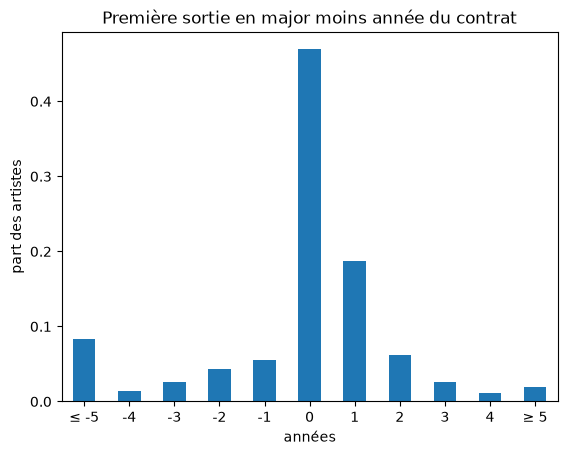

In [13]:
debut = debut_contrat(label_major)
ecart = (premiere_major.reindex(debut.index) - debut).dropna()
ecart = ecart[debut[ecart.index].between(2000, 2023)]
repartition = ecart.clip(-5, 5).value_counts(normalize=True).sort_index()
repartition = repartition.rename({-5: "≤ -5", 5: "≥ 5"}).rename_axis("années")

print(len(ecart), "artistes")
repartition.plot.bar(title="Première sortie en major moins année du contrat", ylabel="part des artistes", rot=0);
repartition.round(2)

Sur 501 artistes, 47 % sortent en major l'année du contrat et 25 % un ou deux ans après. 6 % attendent trois ans ou plus, comme Vampire Weekend (2016 puis 2019). H = 3 couvre donc presque tous les délais entre signature et disque.

Le pic à 0 laisse penser que beaucoup de contrats sont datés d'après le disque lui-même. Le contrat n'est donc pas tout à fait indépendant des sorties, et le rappel et la précision ci-dessus sont sans doute optimistes. 22 % des premières sorties en major précèdent le contrat d'au moins un an. Ce peut être une licence, un label mal rattaché ou un contrat saisi pour une signature plus tardive.

## 5. « + imprint » ou « + rename » ?

On compare les types de liens sans les dates. Un renommage porte la date du changement de nom, pas une période. Lu comme une période, il ne garderait le nouveau nom que l'année du renommage.

In [14]:
renommages = liens[(liens["type_lien"] == "label rename") & liens["begin_date_year"].notna() & liens["end_date_year"].notna()]
print(f"renommages datés : {(renommages['begin_date_year'] == renommages['end_date_year']).mean():.0%} avec la même année de début et de fin")

lignes, positifs_variante, variantes = {}, {}, {}
for variante in ["ownership", "+ imprint", "+ rename"]:
    variantes[variante] = sans_distributeurs(labels_majors(liens, VARIANTES[variante])).assign(debut=-inf, fin=inf)
    s = sorties_du_projet(release, variantes[variante])
    c = cohorte(s, 2021)
    positifs_variante[variante] = set(c[c].index)
    lignes[variante] = {"labels": variantes[variante]["label"].nunique(), "positifs à T0 = 2021": c.sum(), **comparer(s, variantes[variante])}

pd.DataFrame.from_dict(lignes, orient="index").round(2)

renommages datés : 96% avec la même année de début et de fin


,labels,positifs à T0 = 2021,signatures dans la fenêtre,rappel,positifs avec un contrat daté,précision,contrat avant T0,contrat après la fenêtre
ownership,3074,766,117,0.82,124,0.77,0.15,0.07
+ imprint,3682,781,99,0.79,105,0.74,0.17,0.09
+ rename,4814,818,103,0.80,111,0.74,0.18,0.08


In [15]:
en_plus = positifs_variante["+ rename"] - positifs_variante["+ imprint"]
nouveaux = set(variantes["+ rename"]["label"]) - set(variantes["+ imprint"]["label"])
koch = labels_sous(liens, [2543], VARIANTES["+ rename"])  # KOCH Records, la branche américaine de Koch

fenetre = sorties[sorties["artist"].isin(en_plus) & sorties["annee"].between(2021, 2023)]
ajouts = release_label[release_label["label"].isin(nouveaux)].merge(fenetre[["release", "artist"]], on="release")
ajouts = ajouts.drop_duplicates(["artist", "label"])
via_koch = ajouts.loc[ajouts["label"].isin(koch), "artist"].nunique()

print(f"{len(en_plus)} positifs en plus avec + rename, dont {via_koch} par des labels de la branche Koch")
ajouts["label"].map(label["name"]).value_counts().head(10)

66 positifs en plus avec + rename, dont 36 par des labels de la branche Koch


label
Prosthetic Records    14
MNRK Music             9
Capitol Records        5
Dualtone               4
MNRK Heavy             4
XXIM Records           3
eOne                   3
MNRK Music Group       3
Masterworks            2
eOne Heavy             2
Name: count, dtype: int64

« + rename » ajoute 66 positifs, dont 36 par la branche américaine de Koch (Prosthetic, MNRK, eOne, Dualtone). Universal n'a racheté en 2002 qu'une partie européenne de Koch, devenue Koch Universal Music. La branche américaine, indépendante, est passée à Entertainment One. Le renommage de KOCH International en Koch Universal Music relie les deux et rattache tout eOne à Universal. Les 30 autres viennent en partie de vrais labels de majors (Capitol, XXIM, Masterworks).

Les contrats ne départagent pas les variantes. Rappel et précision restent entre 0,74 et 0,82, des écarts de l'ordre de l'erreur d'échantillonnage avec une centaine de signatures. On garde « + imprint ». Sans imprint, Warner Records, le grand label américain de Warner, n'est même pas rattaché à Warner.

## 6. Effet des corrections

In [16]:
am, fdc = id_artiste[CONNUS["Arctic Monkeys"]], id_artiste[CONNUS["Fontaines D.C."]]
VERSIONS = {
    "sans correction": (labels_bruts, 0),
    "disque à moitié en major": (labels_bruts, 0.5),
    "disque entièrement en major": (labels_bruts, 1),
    "sans les distributeurs": (sans_distributeurs(labels_bruts), 0),
    "les deux, sans les dates": (sans_distributeurs(labels_bruts), 0.5),
    "les deux, liens datés (cible du notebook 01)": (label_major, 0.5),
}
lignes = {}
for nom_version, (majors, seuil) in VERSIONS.items():
    s = sorties_du_projet(release, majors, seuil)
    c = cohorte(s, 2021)
    retires = controle.loc[~controle.index.isin(c[c].index), "verdict"]
    premiere = premiere_sortie_major(s)
    mesures = comparer(s, majors)
    lignes[nom_version] = {
        "sorties en major": s["major"].sum(),
        "positifs à T0 = 2021": c.sum(),
        "faux retirés": (retires == "faux").sum(),
        "justes retirés": (retires == "juste").sum(),
        "rappel": mesures["rappel"],
        "précision": mesures["précision"],
        "Vampire Weekend": premiere.get(vw),
        "Arctic Monkeys": premiere.get(am),
        "Fontaines D.C.": premiere.get(fdc),
    }

pd.DataFrame.from_dict(lignes, orient="index").round(2).astype({"Arctic Monkeys": "Int64", "Fontaines D.C.": "Int64"})

,sorties en major,positifs à T0 = 2021,faux retirés,justes retirés,rappel,précision,Vampire Weekend,Arctic Monkeys,Fontaines D.C.
sans correction,469413,835,0,0,0.77,0.74,2008,2013,2023
disque à moitié en major,460709,842,1,0,0.79,0.74,2019,<NA>,2023
disque entièrement en major,407558,841,3,0,0.75,0.64,2019,<NA>,2023
sans les distributeurs,460799,771,2,0,0.77,0.75,2008,2013,2023
"les deux, sans les dates",452177,781,3,0,0.79,0.74,2019,<NA>,2023
"les deux, liens datés (cible du notebook 01)",335406,719,3,1,0.78,0.74,2019,<NA>,<NA>


Sans les dates, les deux premières corrections retirent 3 faux de l'échantillon et aucun juste. Elles gardent le rappel et la précision face aux contrats (0,79 et 0,74). Elles règlent aussi Vampire Weekend et Arctic Monkeys.

- Disque au moins à moitié en major. Exiger toutes les éditions retire 3 faux au lieu d'1, mais fait tomber la précision face aux contrats de 0,74 à 0,64. On garde la moitié.
- Sans les distributeurs. 2 faux retirés, et 771 positifs au lieu de 835 à T0 = 2021.
- Liens datés. Les sorties en major passent de 452 177 à 335 406, un quart de moins. Les positifs passent de 781 à 719 à T0 = 2021. Fontaines D.C. est réglé, et le rappel et la précision ne bougent presque pas (0,78 et 0,74). Mais un juste est retiré, Drims part avec « Universal ».

In [17]:
avec_distributeurs = sorties_du_projet(release, labels_bruts)
c = cohorte(avec_distributeurs, 2021)
sans = cohorte(sorties_du_projet(release, sans_distributeurs(labels_bruts)), 2021)
retires = c[c].index.difference(sans[sans].index)
distributeurs = set(labels_bruts["label"]) - set(sans_distributeurs(labels_bruts)["label"])

fenetre = avec_distributeurs[avec_distributeurs["artist"].isin(retires) & avec_distributeurs["major"] & avec_distributeurs["annee"].between(2021, 2023)]
causes = release_label[release_label["release"].isin(fenetre["release"]) & release_label["label"].isin(distributeurs)]
causes = causes.merge(fenetre[["release", "artist"]], on="release").drop_duplicates(["artist", "label"])

print(len(retires), "positifs retirés en écartant les distributeurs")
causes["label"].map(label["name"]).value_counts().head(12)

80 positifs retirés en écartant les distributeurs


label
Warner Music Korea                             16
Play Two                                       10
Virgin Music Label & Artist Services            9
AWAL                                            9
Virgin Music UK LAS (S&D)                       8
Chapter ONE                                     5
300 Entertainment                               5
V2 Records Benelux                              5
Warner Music Australia                          2
INgrooves                                       2
Virgin Music Label & Artist Services France     1
Foundation Media, LLC                           1
Name: count, dtype: int64

Les 80 positifs retirés ainsi viennent surtout de services de distribution (Warner Music Korea, Virgin Music Label & Artist Services, AWAL, INgrooves). Quelques filiales nationales typées Distributor partent avec (Warner Music Australia), c'est le prix d'une règle simple.

Restent les homonymes, les labels absents et les liens mal datés dans la base. Voici les positifs de 2021 perdus en datant les liens, par cause.

In [18]:
sans_dates = sorties_du_projet(release, sans_distributeurs(labels_bruts))
avant, apres = cohorte(sans_dates, 2021), cohorte(sorties, 2021)
perdus = avant[avant].index.difference(apres[apres].index)
premieres = sans_dates[sans_dates["artist"].isin(perdus) & sans_dates["major"] & sans_dates["annee"].between(2021, 2023)]
premieres = premieres.sort_values("annee").drop_duplicates("artist")[["artist", "release", "annee"]]
premieres = premieres.merge(release_label[release_label["label"].isin(labels_bruts["label"])], on="release").drop_duplicates("artist")
premieres = premieres.join(label_major.groupby("label").agg(debut=("debut", "min"), fin=("fin", "max")), on="label")
premieres["cause"] = "label hors de l'arbre daté"
premieres.loc[premieres["fin"] < premieres["annee"], "cause"] = "lien fini avant la sortie"
premieres.loc[premieres["debut"] > premieres["annee"], "cause"] = "label racheté après la sortie"
print(len(perdus), "positifs de 2021 perdus en datant les liens")
display(premieres["cause"].value_counts())

FINS = {"Chrysalis": "vente", "Flying Nun Records": "vente", "Universal": "artefact", "Universal Music Australia Limited": "artefact"}
finis = premieres[premieres["cause"] == "lien fini avant la sortie"].groupby("label").agg(positifs=("artist", "size"), fin=("fin", "first"))
finis.insert(0, "nom", finis.index.map(label["name"]))
finis["verdict"] = finis["nom"].map(FINS).fillna("non vérifié")
display(finis.sort_values("positifs", ascending=False))
display(finis.groupby("verdict")["positifs"].sum())

releases_perdues = set(sans_dates.loc[sans_dates["major"], "release"]) - set(sorties.loc[sorties["major"], "release"])
avec_universal = sans_dates["release"].isin(releases_perdues) & sans_dates["release"].isin(release_label.loc[release_label["label"] == 59382, "release"])
print((avec_universal & sans_dates["annee"].between(2014, 2023)).sum(), "sorties gardées de 2014 à 2023 perdent la major avec « Universal »")

62 positifs de 2021 perdus en datant les liens


cause
lien fini avant la sortie        30
label racheté après la sortie    24
label hors de l'arbre daté        8
Name: count, dtype: int64

,nom,positifs,fin,verdict
label,,,,
795,Chrysalis,9,2016.0,vente
59382,Universal,7,2000.0,artefact
121651,HEXAGON,3,2019.0,non vérifié
7108,Flying Nun Records,2,2009.0,vente
2610,tôt Ou tard,2,2002.0,non vérifié
16823,Liberation Records,2,2009.0,non vérifié
64610,Big Shot,1,2013.0,non vérifié
135558,F.C.L.S.,1,2019.0,non vérifié
157211,VF Musiques,1,2002.0,non vérifié


verdict
artefact        8
non vérifié    11
vente          11
Name: positifs, dtype: Int64

650 sorties gardées de 2014 à 2023 perdent la major avec « Universal »


En datant les liens, la cohorte 2021 perd 62 positifs. 24 viennent d'un label racheté par une major après leur sortie, la date est alors juste. 8 viennent d'un label qui, d'après les dates, n'a jamais été à une major. 30 viennent d'un lien fini avant la sortie, sans renommage proche.

Chrysalis et Flying Nun sont de vraies ventes, soit 11 positifs. Warner a vendu Flying Nun en 2009. « Universal » et Universal Music Australia sont des artefacts, ces labels sont toujours chez Universal. Ils font 8 positifs, dont 7 pour « Universal ». Ce label fait aussi perdre la major à 650 sorties gardées de 2014 à 2023. Les 11 autres viennent de labels non vérifiés. Aucune règle simple ne sépare ces artefacts des vraies ventes, ils restent une limite de la cible.

## Sources

- Vampire Weekend chez Columbia, https://stereogum.com/1911974/vampire-weekend-reportedly-sign-to-columbia-for-lp4/news
- La vente de Chrysalis par Warner, https://musicbusinessworldwide.com/warner-sells-chrysalis-records-back-to-chris-wright-and-blue-raincoat
- La vente de Flying Nun par Warner, https://en.wikipedia.org/wiki/Flying_Nun_Records
- La branche américaine de Koch, https://en.wikipedia.org/wiki/Koch_Entertainment
- Le rachat d'AWAL par Sony, https://www.musicbusinessworldwide.com/sony-music-completes-430m-buyout-of-awal/
- Le rachat de 300 Entertainment par Warner, https://www.marketscreener.com/quote/stock/WARNER-MUSIC-GROUP-CORP-107768549/news/Warner-Music-Group-Corp-acquired-300-Entertainment-37361078
- Les positifs vérifiés à la main
  - Price, https://complex.com/music/price-ep-the-price-stream
  - Cynthia Erivo, https://universalmusic.ca/press-releases/singer-songwriter-cynthia-erivo-announces-debut-album-ch-1-vs-1-set-for-release-september-17
  - KUU, https://909originals.com/2020/12/08/tapping-into-the-balearic-spirit-909originals-catches-up-with-kuu/
  - Morgan Wade, https://musicrow.com/2021/08/morgan-wade-signs-deal-with-arista-nashville/
  - Armani White, https://variety.com/2022/music/news/em-beihold-sony-publishing-billie-eilish-armani-white-def-jam-1235327602
  - Misery Index, https://blabbermouth.net/news/misery-index-signs-with-century-media-records
  - Tems, https://hitsdailydouble.com/news&id=328284&title=TEMS-SIGNS-WITH-SINCE-93-RCA-LANDS-APPLE-MUSIC-UP-NEXT
  - Nate Smith, https://en.wikipedia.org/wiki/Nate_Smith_(album)
  - Faouzia, https://en.wikipedia.org/wiki/Faouzia
  - Mick Jenkins, https://en.wikipedia.org/wiki/The_Patience
  - MIST, https://en.wikipedia.org/wiki/Mist_(rapper)